In [2]:
import pandas as pd
import glob

files = glob.glob('manual_labeled*')
print(files)

lab = pd.read_csv(files[0])
print(lab.shape)
print(lab.columns.tolist())
print(lab['manual_label'].value_counts(dropna=False))

['manual_labeled.csv 2.csv']
(102, 4)
['id', 'ticker', 'headline_clean', 'manual_label']
manual_label
p      55
u      24
n      22
NaN     1
Name: count, dtype: int64


In [3]:
import numpy as np
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

df = pd.read_csv('financial_news_sentiment_clean.csv')
print(df.shape)

lab['manual'] = lab['manual_label'].map({'p': 'positive', 'n': 'negative', 'u': 'neutral'})
print('Unlabeled ids:', lab.loc[lab['manual'].isna(), 'id'].tolist())
lab = lab.dropna(subset=['manual'])

# الدمج بالـ id (مو بالنص) عشان ترميز Excel ما يأثر
m = lab.merge(df, left_on='id', right_index=True, suffixes=('', '_df'))
print('ticker mismatches:', (m['ticker'] != m['ticker_df']).sum(), '| n =', len(m))

base = SentimentIntensityAnalyzer()
fin = SentimentIntensityAnalyzer()
fin.lexicon.update({
    'record': 2.0, 'high': 1.5, 'rally': 2.5, 'surge': 2.5, 'soar': 2.5,
    'beat': 2.0, 'beats': 2.0, 'upgrade': 2.0, 'gain': 1.8, 'gains': 1.8,
    'falls': -2.0, 'fall': -2.0, 'drop': -2.0, 'plunge': -3.0, 'slump': -2.5,
    'sell-off': -2.5, 'selloff': -2.5, 'downgrade': -2.0, 'bearish': -2.0,
    'bullish': 2.0, 'miss': -2.0, 'misses': -2.0, 'lawsuit': -2.0, 'trillion': 0,
})
to_label = lambda s: 'positive' if s >= 0.05 else ('negative' if s <= -0.05 else 'neutral')

text = m['headline_clean_df']
preds = {
    'VADER default (clean text)': text.apply(lambda h: to_label(base.polarity_scores(h)['compound'])),
    'VADER + financial lexicon (clean text)': text.apply(lambda h: to_label(fin.polarity_scores(h)['compound'])),
    'VADER + lexicon (raw text, original pipeline)': m['score_raw'].apply(to_label),
}

labels = ['negative', 'neutral', 'positive']
y = m['manual']
rows = []
for name, p in preds.items():
    print('=' * 60); print(name)
    print(classification_report(y, p, labels=labels, zero_division=0, digits=3))
    print(pd.DataFrame(confusion_matrix(y, p, labels=labels),
                       index=[f'true_{l}' for l in labels], columns=[f'pred_{l}' for l in labels]))
    rows.append({'model': name, 'accuracy': accuracy_score(y, p),
                 'macro_F1': f1_score(y, p, average='macro', labels=labels, zero_division=0)})

print('=' * 60)
print(pd.DataFrame(rows).round(3).to_string(index=False))
print('Always-positive baseline accuracy:', round((y == 'positive').mean(), 3))

(296, 11)
Unlabeled ids: [216]
ticker mismatches: 0 | n = 101
VADER default (clean text)
              precision    recall  f1-score   support

    negative      0.562     0.409     0.474        22
     neutral      0.250     0.542     0.342        24
    positive      0.606     0.364     0.455        55

    accuracy                          0.416       101
   macro avg      0.473     0.438     0.423       101
weighted avg      0.512     0.416     0.432       101

               pred_negative  pred_neutral  pred_positive
true_negative              9             9              4
true_neutral               2            13              9
true_positive              5            30             20
VADER + financial lexicon (clean text)
              precision    recall  f1-score   support

    negative      0.529     0.409     0.462        22
     neutral      0.239     0.458     0.314        24
    positive      0.632     0.436     0.516        55

    accuracy                          0.4

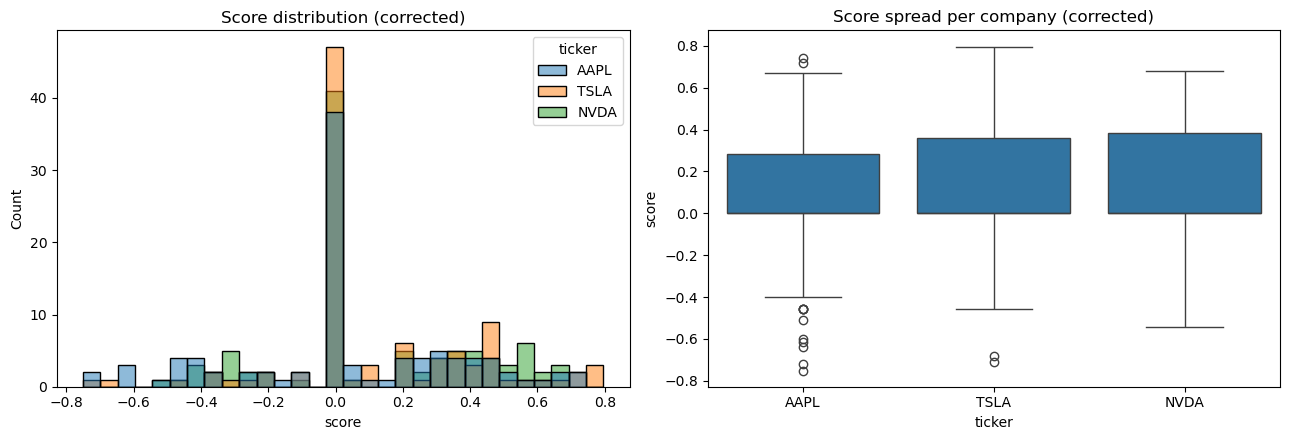

In [4]:
import matplotlib.pyplot as plt, seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x='score', hue='ticker', bins=30, ax=ax[0])
ax[0].set_title('Score distribution (corrected)')
sns.boxplot(data=df, x='ticker', y='score', ax=ax[1])
ax[1].set_title('Score spread per company (corrected)')
plt.tight_layout(); plt.savefig('eda_overview_corrected.png', dpi=150); plt.show()